# Test final: ResNet50 y VGG19 con su mejor configuración de Optuna

Cada red se entrena con **las 900 imágenes** usando la mejor configuración que encontró su búsqueda, y se evalúa en
el test con **el umbral elegido en el cross validation** de esa búsqueda (no se ajusta nada mirando el test).

| Red | lr | Bloques | Calentamiento | Intensidad aug | Dropout | Fases |
|---|---|---|---|---|---|---|
| ResNet50 | 4,77e-5 | `conv5 + conv4` | 10 | 0,168 | 0,679 | 10 cabeza → 10 + `conv5` → 10 + `conv4` (lr / 2) |
| VGG19 | 8,00e-5 | `block5` | 10 | 0,255 | 0,311 | 10 cabeza → 20 + `block5` |

El resto es igual que en las búsquedas: batch 32, entrada 256×256, cabeza `GlobalAveragePooling2D` + `Dense(128)` +
dropout + sigmoide, Adam con *cosine decay* por fase, `class_weight`, BatchNorm congelada, learning rate del
calentamiento 1e-4 y semilla 41.

**Antes de correrlo:**

1. Subí a `/content` los dos zips del test: `test_paneles_200.zip` y `Test_Etiquetado.zip`.
2. Los umbrales se leen de los `configuracion_elegida.json` que guardó cada búsqueda:
   - **ResNet50:** ya está en Drive, en `MyDrive/paneles/optuna_resnet50/`.
   - **VGG19:** está en la salida de la versión de Kaggle (`optuna_vgg19/configuracion_elegida.json`). Descargalo
     desde la pestaña *Output* y subilo a Drive en `MyDrive/paneles/optuna_vgg19/`, o a `/content`.

   Si preferís, podés escribir los umbrales a mano en la celda de configuración.

**Tiempo estimado en la T4:** unos 10 minutos (dos entrenamientos de 30 épocas).

## Preparación

In [ ]:
import os
from google.colab import drive



# Si el repo ya está clonado (por ejemplo, al volver a hacer Run all), no se vuelve a clonar
if not os.path.isdir("/content/repo"):
    !git clone https://github.com/ana-castillo-zuain/procesamiento-de-imagenes.git /content/repo
%cd /content/repo

Cloning into '/content/repo'...
remote: Enumerating objects: 2367, done.
remote: Total 2367 (delta 0), reused 0 (delta 0), pack-reused 2367 (from 2)
Receiving objects: 100% (2367/2367), 150.38 MiB | 18.76 MiB/s, done.
Resolving deltas: 100% (51/51), done.
Updating files: 100% (9938/9938), done.
/content/repo


In [ ]:
import gc
import pickle
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# La GPU pide memoria a medida que la necesita (evita errores de memoria al encadenar entrenamientos).
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

from tensorflow import keras
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input, Lambda
import json
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Datos

Las dos primeras celdas son las del notebook principal: arman y validan los 3 folds y cargan las 900 imágenes.
La tercera carga el test.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

# --- Rutas (relativas a la raíz del repo: en Colab, hacer antes %cd /content/repo)
RAIZ = Path(".")
DIR_IMG = RAIZ / "data" / "raw" / "images"
DIR_LAB = RAIZ / "data" / "raw" / "labels"
DIR_SPLITS = RAIZ / "data" / "splits"

FOLDS = ["solarpanels_val", "geo_kingston_val", "PV01_val"]

if not DIR_IMG.is_dir() or not DIR_LAB.is_dir() or not DIR_SPLITS.is_dir():
    raise FileNotFoundError("No encontré data/raw y data/splits en %s. Pasate a la raíz del repo "
                            "(por ejemplo, %%cd /content/repo) y volvé a correr." % Path.cwd())


def grupo_de(nombre: str) -> str:
    """Los nombres de archivo delatan de qué fuente viene cada imagen."""
    if nombre.startswith("PV01"):           return "PV01"
    if nombre.startswith("solarpanels_hd"): return "solarpanels_hd"
    if nombre.startswith("kingston2"):      return "kingston2"
    if nombre.startswith("kingston_"):      return "kingston"
    return "geo_unknown"


def leer_yolo(ruta):
    """Lee un .txt en formato YOLO -> lista de (clase, cx, cy, w, h) normalizados."""
    cajas = []
    for linea in Path(ruta).read_text().splitlines():
        if not linea.strip():
            continue
        partes = linea.split()
        cajas.append((int(float(partes[0])), *map(float, partes[1:5])))
    return cajas


# Clases 1 y 2 no son paneles. Si un .txt sólo tiene esas filas, la imagen es negativa.
CLASES_NEGATIVAS = {1, 2}


def es_panel(cls):
    return cls not in CLASES_NEGATIVAS


# Todas las imágenes y su label calculado desde los labels crudos (para la validación 6)
TODAS = sorted(p.stem for p in DIR_IMG.glob("*.png"))
LABEL_RAW = {n: int(any(es_panel(c[0]) for c in leer_yolo(DIR_LAB / (n + ".txt")))) for n in TODAS}
print("data/raw: %d imágenes | %d positivas | %d negativas"
      % (len(TODAS), sum(LABEL_RAW.values()), len(TODAS) - sum(LABEL_RAW.values())))


def leer_lista(ruta):
    """Líneas no vacías de un train.txt / val.txt (rutas relativas a la raíz del repo)."""
    return [l.strip() for l in Path(ruta).read_text().splitlines() if l.strip()]


def tiene_cajas(ruta):
    """1 si el .txt limpio tiene al menos una línea no vacía, 0 si está vacío."""
    return int(any(l.strip() for l in Path(ruta).read_text().splitlines()))


def armar_fold(fold):
    """Una fila por imagen del fold: ruta, nombre, fuente, split y ruta de su etiqueta limpia."""
    dir_fold = DIR_SPLITS / fold
    filas = []
    for sp in ("train", "val"):
        for ruta in leer_lista(dir_fold / (sp + ".txt")):
            nombre = Path(ruta).stem
            filas.append(dict(ruta_imagen=ruta, nombre=nombre, fuente=grupo_de(nombre), split=sp,
                              ruta_label=(dir_fold / "labels" / sp / (nombre + ".txt")).as_posix()))
    return pd.DataFrame(filas, columns=["ruta_imagen", "nombre", "fuente", "split", "ruta_label"])


def validar_estructura(fold, df):
    """Validaciones 1 a 5: repetidas, fuentes cruzadas, archivos faltantes, huérfanos y cobertura."""
    errores = []
    tr, va = df[df.split == "train"], df[df.split == "val"]

    for sp, sub in (("train", tr), ("val", va)):
        if sub.empty:
            errores.append("%s está vacío" % sp)
        rep = sorted(set(sub.nombre[sub.nombre.duplicated()]))
        if rep:
            errores.append("%s tiene %d imágenes repetidas: %s" % (sp, len(rep), rep[:5]))
    cruzadas = sorted(set(tr.nombre) & set(va.nombre))
    if cruzadas:
        errores.append("%d imágenes en train y val a la vez: %s" % (len(cruzadas), cruzadas[:5]))

    fuentes = sorted(set(tr.fuente) & set(va.fuente))
    if fuentes:
        errores.append("fuentes en train y val a la vez: %s" % fuentes)

    sin_imagen = [r for r in df.ruta_imagen if not Path(r).is_file()]
    if sin_imagen:
        errores.append("%d imágenes listadas no existen: %s" % (len(sin_imagen), sin_imagen[:5]))
    sin_label = [r for r in df.ruta_label if not Path(r).is_file()]
    if sin_label:
        errores.append("%d imágenes sin etiqueta: %s" % (len(sin_label), sin_label[:5]))

    for sp, sub in (("train", tr), ("val", va)):
        en_disco = {p.stem for p in (DIR_SPLITS / fold / "labels" / sp).glob("*.txt")}
        huerfanas = sorted(en_disco - set(sub.nombre))
        if huerfanas:
            errores.append("labels/%s tiene %d etiquetas huérfanas: %s" % (sp, len(huerfanas), huerfanas[:5]))

    afuera = sorted(set(TODAS) - set(df.nombre))
    if afuera:
        errores.append("%d imágenes de data/raw no están en ningún split: %s" % (len(afuera), afuera[:5]))
    ajenas = sorted(set(df.nombre) - set(TODAS))
    if ajenas:
        errores.append("%d imágenes listadas no están en data/raw/images: %s" % (len(ajenas), ajenas[:5]))

    if errores:
        raise ValueError("[%s] validación fallida:\n  - %s" % (fold, "\n  - ".join(errores)))


def validar_contra_raw(fold, df):
    """Validación 6: el label de data/splits tiene que coincidir con el calculado desde data/raw/labels."""
    raw = df.nombre.map(LABEL_RAW)
    dif = df[df.label != raw]
    if len(dif):
        tabla = pd.DataFrame(dict(fold=fold, nombre=dif.nombre, split=dif.split,
                                  label_splits=dif.label, label_raw=raw[dif.index]))
        print(tabla.to_string(index=False))
        raise ValueError("[%s] %d imágenes con label distinto entre data/splits y data/raw/labels"
                         % (fold, len(dif)))


# Primero se arman y validan los tres folds. Recién después (sección 5) se escribe algo en disco.
DFS = {}
for fold in FOLDS:
    df = armar_fold(fold)
    validar_estructura(fold, df)
    df["label"] = [tiene_cajas(r) for r in df.ruta_label]
    validar_contra_raw(fold, df)
    DFS[fold] = df
    print("%-17s OK  (train %d, val %d)"
          % (fold, (df.split == "train").sum(), (df.split == "val").sum()))

data/raw: 900 imágenes | 805 positivas | 95 negativas
solarpanels_val   OK  (train 584, val 316)
geo_kingston_val  OK  (train 794, val 106)
PV01_val          OK  (train 422, val 478)


In [ ]:
from concurrent.futures import ThreadPoolExecutor


def cargar_rgb(ruta):
    """Imagen como RGB uint8 (algunas PNG están en modo paleta)."""
    with Image.open(ruta) as im:
        return np.array(im.convert("RGB"))


# Cada imagen se lee una sola vez (en paralelo) y después cada fold toma las suyas
rutas = sorted({r for df in DFS.values() for r in df.ruta_imagen})
with ThreadPoolExecutor() as ex:
    IMG = dict(zip(rutas, ex.map(cargar_rgb, rutas)))
print("%d imágenes en memoria" % len(IMG))


def xy(fold, split):
    sub = DFS[fold][DFS[fold].split == split]
    X = np.stack([IMG[r] for r in sub.ruta_imagen])        # uint8 0-255, (N, 256, 256, 3)
    y = sub.label.to_numpy().astype("float32")              # 1 = con paneles, 0 = sin paneles
    return X, y


X_train_1, y_train_1 = xy("solarpanels_val", "train")
X_val_1,   y_val_1   = xy("solarpanels_val", "val")
X_train_2, y_train_2 = xy("geo_kingston_val", "train")
X_val_2,   y_val_2   = xy("geo_kingston_val", "val")
X_train_3, y_train_3 = xy("PV01_val", "train")
X_val_3,   y_val_3   = xy("PV01_val", "val")

for i, (Xt, yt, Xv, yv) in enumerate([(X_train_1, y_train_1, X_val_1, y_val_1),
                                      (X_train_2, y_train_2, X_val_2, y_val_2),
                                      (X_train_3, y_train_3, X_val_3, y_val_3)], start=1):
    print(f"Fold {i}: train {Xt.shape} pos {int(yt.sum())} neg {int(len(yt) - yt.sum())} | "
          f"val {Xv.shape} pos {int(yv.sum())} neg {int(len(yv) - yv.sum())}")

900 imágenes en memoria
Fold 1: train (584, 256, 256, 3) pos 521 neg 63 | val (316, 256, 256, 3) pos 284 neg 32
Fold 2: train (794, 256, 256, 3) pos 761 neg 33 | val (106, 256, 256, 3) pos 44 neg 62
Fold 3: train (422, 256, 256, 3) pos 328 neg 94 | val (478, 256, 256, 3) pos 477 neg 1


In [ ]:
from PIL import Image

DIR_TEST = Path("data/test")   # dentro del repo: etiquetas.csv y lote_1 ... lote_5

if not (DIR_TEST / "etiquetas.csv").is_file():
    raise FileNotFoundError(f"No encontré {DIR_TEST / 'etiquetas.csv'}. ¿Está subida la carpeta data/test al repo?")

ETIQUETAS_TEST = pd.read_csv(DIR_TEST / "etiquetas.csv")
faltan = [a for a in ETIQUETAS_TEST.archivo if not (DIR_TEST / a).is_file()]
if faltan:
    raise FileNotFoundError(f"Faltan {len(faltan)} imágenes del test en {DIR_TEST}, por ejemplo: {faltan[:3]}")

X_test = np.stack([cargar_rgb(DIR_TEST / a) for a in ETIQUETAS_TEST.archivo])
y_test = (ETIQUETAS_TEST.etiqueta.str.strip().str.lower() == "con").astype(int).to_numpy()
print(f"Test: {len(y_test)} imágenes | {y_test.sum()} con paneles | {len(y_test) - y_test.sum()} sin paneles")

Test: 200 imágenes | 125 con paneles | 75 sin paneles


## Configuraciones y umbrales

In [ ]:
DIR_SALIDA = Path("/content/drive/MyDrive/paneles/test_final")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

SEED_VALUE = 41
IMG_SIZE = 256
BATCH_SIZE = 32
DENSE_UNITS = 128
EPOCAS_FT = 20
LR_CALENTAMIENTO = 1e-4

MODELOS = {
    "ResNet50": dict(
        cfg=dict(lr=4.767954449336301e-05, bloques=2, calentamiento=10,
                 intensidad=0.16793842699195044, dropout=0.6788667755320483),
        jsons=[Path("/content/drive/MyDrive/paneles/optuna_resnet50/configuracion_elegida.json"),
               Path("/content/configuracion_elegida_resnet50.json")],
        umbral=0.90,            # o escribilo a mano, por ejemplo 0.72
    ),
    "VGG19": dict(
        cfg=dict(lr=7.997321998494855e-05, bloques=1, calentamiento=10,
                 intensidad=0.2549768923127999, dropout=0.31131144348199524),
        jsons=[Path("/content/drive/MyDrive/paneles/optuna_vgg19/configuracion_elegida.json"),
               Path("/content/configuracion_elegida.json"),
               Path("/content/configuracion_elegida_vgg19.json")],
        umbral=0.90,
    ),
}

# Umbral elegido en el cross validation de cada búsqueda (del configuracion_elegida.json, si no se escribió a mano)
for red, m in MODELOS.items():
    if m["umbral"] is not None:
        print(f"{red}: umbral escrito a mano = {m['umbral']:.2f}")
        continue
    archivo = next((j for j in m["jsons"] if j.is_file()), None)
    if archivo is None:
        raise FileNotFoundError(f"No encontré el configuracion_elegida.json de {red} (busqué en {[str(j) for j in m['jsons']]}). "
                                "Subilo a una de esas rutas o escribí el umbral a mano en MODELOS.")
    guardado = json.loads(archivo.read_text())
    if any(abs(guardado["config"][k] - m["cfg"][k]) > 1e-9 for k in m["cfg"]):
        print(f"ATENCIÓN {red}: la configuración del json no coincide con la de MODELOS:\n  json:    {guardado['config']}\n"
              f"  MODELOS: {m['cfg']}")
    m["umbral"] = float(guardado["umbral"])
    print(f"{red}: umbral del cross validation = {m['umbral']:.2f} (de {archivo})")

ResNet50: umbral escrito a mano = 0.90
VGG19: umbral escrito a mano = 0.90


## Modelo y entrenamiento con las 900 imágenes

Es el mismo modelo y el mismo esquema de fases que en las búsquedas de Optuna.

In [ ]:
REDES = {
    "ResNet50": dict(clase=tf.keras.applications.ResNet50,
                     preprocesar=tf.keras.applications.resnet50.preprocess_input, bloques=("conv5", "conv4")),
    "VGG19":    dict(clase=tf.keras.applications.VGG19,
                     preprocesar=tf.keras.applications.vgg19.preprocess_input, bloques=("block5", "block4")),
}


def capas_aumentacion(intensidad):
    return Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),
        tf.keras.layers.RandomRotation(1.25 * intensidad, fill_mode="reflect"),
        tf.keras.layers.RandomZoom(intensidad, fill_mode="reflect"),
        tf.keras.layers.RandomBrightness(intensidad, value_range=(0, 255)),
        tf.keras.layers.RandomContrast(intensidad),
    ], name="aumentacion")


def construir(red, cfg):
    r = REDES[red]
    forma = (IMG_SIZE, IMG_SIZE, 3)
    base = r["clase"](input_shape=forma, include_top=False, weights="imagenet")
    entrada = Input(shape=forma)
    x = capas_aumentacion(cfg["intensidad"])(entrada)
    x = Lambda(r["preprocesar"], name="preprocesamiento")(x)
    x = base(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(DENSE_UNITS, activation="relu")(x)
    x = Dropout(cfg["dropout"])(x)
    salida = Dense(1, activation="sigmoid")(x)
    return Model(entrada, salida, name=red), base


def configurar_entrenables(base, desde):
    inicio = len(base.layers) if desde is None else next(
        i for i, capa in enumerate(base.layers) if capa.name.startswith(desde))
    base.trainable = True
    for i, capa in enumerate(base.layers):
        capa.trainable = i >= inicio and not isinstance(capa, tf.keras.layers.BatchNormalization)


def fases_de(red, cfg):
    ultimo, anteultimo = REDES[red]["bloques"]
    fases = []
    if cfg["calentamiento"] > 0:
        fases.append(dict(desde=None, epocas=cfg["calentamiento"], lr=LR_CALENTAMIENTO, nombre="solo cabeza"))
    if cfg["bloques"] == 1:
        fases.append(dict(desde=ultimo, epocas=EPOCAS_FT, lr=cfg["lr"], nombre=f"cabeza + {ultimo}"))
    elif cfg["calentamiento"] == 0:
        fases.append(dict(desde=anteultimo, epocas=EPOCAS_FT, lr=cfg["lr"], nombre=f"cabeza + {ultimo} + {anteultimo}"))
    else:
        mitad = EPOCAS_FT // 2
        fases.append(dict(desde=ultimo, epocas=mitad, lr=cfg["lr"], nombre=f"cabeza + {ultimo}"))
        fases.append(dict(desde=anteultimo, epocas=EPOCAS_FT - mitad, lr=cfg["lr"] / 2,
                          nombre=f"cabeza + {ultimo} + {anteultimo}"))
    return fases


def entrenar_final(red, cfg, X, y):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_VALUE)
    n, n_pos = len(y), int(y.sum())
    pesos = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}
    model, base = construir(red, cfg)
    epoca = 0
    for fase in fases_de(red, cfg):
        configurar_entrenables(base, fase["desde"])
        pasos = int(np.ceil(n / BATCH_SIZE)) * fase["epocas"]
        schedule = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=fase["lr"], decay_steps=pasos)
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=schedule),
                      loss=tf.keras.losses.BinaryCrossentropy(), metrics=[tf.keras.metrics.AUC(name="auc")])
        print(f"{red} | {fase['nombre']} | {fase['epocas']} épocas | lr {fase['lr']:.2e}")
        model.fit(X, y, initial_epoch=epoca, epochs=epoca + fase["epocas"], batch_size=BATCH_SIZE,
                  class_weight=pesos, shuffle=True, verbose=2)
        epoca += fase["epocas"]
    return model


# Las 900 imágenes de entrenamiento
RUTAS = sorted(IMG)
X_todo = np.stack([IMG[r] for r in RUTAS])
y_todo = np.array([LABEL_RAW[Path(r).stem] for r in RUTAS], dtype="float32")
print(f"Entrenamiento: {len(y_todo)} imágenes | {int(y_todo.sum())} con paneles | {int(len(y_todo) - y_todo.sum())} sin paneles")

PROB_TEST = {}
for red, m in MODELOS.items():
    archivo = DIR_SALIDA / f"prob_test_{red}.npy"
    if archivo.is_file():
        PROB_TEST[red] = np.load(archivo)
        print(f"{red}: probabilidades del test cargadas de Drive")
        continue
    model = entrenar_final(red, m["cfg"], X_todo, y_todo)
    PROB_TEST[red] = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    np.save(archivo, PROB_TEST[red])
    model.save_weights(str(DIR_SALIDA / f"modelo_final_{red}.weights.h5"))
    del model
    gc.collect()

Entrenamiento: 900 imágenes | 805 con paneles | 95 sin paneles
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 | solo cabeza | 10 épocas | lr 1.00e-04
Epoch 1/10
29/29 - 21s - 741ms/step - auc: 0.5512 - loss: 0.9428
Epoch 2/10
29/29 - 4s - 145ms/step - auc: 0.7585 - loss: 0.6152
Epoch 3/10
29/29 - 4s - 150ms/step - auc: 0.8395 - loss: 0.4981
Epoch 4/10
29/29 - 4s - 149ms/step - auc: 0.8660 - loss: 0.4615
Epoch 5/10
29/29 - 4s - 147ms/step - auc: 0.8781 - loss: 0.4361
Epoch 6/10
29/29 - 4s - 148ms/step - auc: 0.8825 - loss: 0.4264
Epoch 7/10
29/29 - 4s - 153ms/step - auc: 0.8797 - loss: 0.4325
Epoch 8/10
29/29 - 5s - 159ms/step - auc: 0.8998 - loss: 0.3957
Epoch 9/10
29/29 - 5s - 172ms/step - auc: 0.9093 - loss: 0.3777
Epoch 10/10
29/29 - 4s - 154ms/step - auc: 0.8979 - loss: 0.4053
ResNet50 | cabeza + conv5 | 10 épocas | lr 4.77e-05
Epoch 11/20
29/29 - 15s - 510ms/step - auc: 0.8796 - loss: 0.4461
Epoch 12/20
29/29 - 5s - 189ms/step - auc: 0.9296 - loss: 0.3367
Epoch 13/20


## Resultados en el test

Métricas con el umbral del cross validation (y con 0,5 como referencia). Precision, recall y F1 son de la clase
"con paneles". El test tiene un 62,5 % de imágenes con paneles, contra el 89 % del entrenamiento: la balanced accuracy
no depende de esa proporción, pero la accuracy y el F1 sí, así que no se comparan directamente con el cross validation.

In [ ]:
def metricas(y, p, umbral):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), auc=roc_auc_score(y, p), accuracy=accuracy_score(y, pred),
                balanced_accuracy=balanced_accuracy_score(y, pred), recall_sin=tn / (tn + fp),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))


ETIQUETAS_TEST["lote"] = ETIQUETAS_TEST.archivo.str.split("/").str[0]
filas, por_lote = [], []
for red, m in MODELOS.items():
    p = PROB_TEST[red]
    for nombre_umbral, u in (("cross validation", m["umbral"]), ("0,5", 0.5)):
        filas.append(dict(red=red, umbral=f"{u:.2f} ({nombre_umbral})", **metricas(y_test, p, u)))
    for lote, idx in ETIQUETAS_TEST.groupby("lote").groups.items():
        por_lote.append(dict(red=red, lote=lote, **metricas(y_test[idx], p[idx], m["umbral"])))
    ETIQUETAS_TEST[f"prob_{red}"] = p
    ETIQUETAS_TEST[f"pred_{red}"] = np.where(p >= m["umbral"], "con", "sin")

RESULTADOS_TEST = pd.DataFrame(filas)
print(RESULTADOS_TEST.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("\nPor lote (umbral del cross validation):")
print(pd.DataFrame(por_lote).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

RESULTADOS_TEST.to_csv(DIR_SALIDA / "resultados_test.csv", index=False)
ETIQUETAS_TEST.to_csv(DIR_SALIDA / "predicciones_test.csv", index=False)

# Solo para el análisis: el mejor umbral posible en el test (no se usa para elegir nada)
grilla = np.round(np.arange(0.05, 0.96, 0.01), 2)
for red in MODELOS:
    ba = [balanced_accuracy_score(y_test, (PROB_TEST[red] >= u).astype(int)) for u in grilla]
    print(f"\nSolo análisis, {red}: el mejor umbral en el test habría sido {grilla[int(np.argmax(ba))]:.2f} "
          f"(balanced accuracy {max(ba):.3f})")

     red                  umbral  precision  recall    f1   auc  accuracy  balanced_accuracy  recall_sin  tn  fp  fn  tp
ResNet50 0.90 (cross validation)      0.742   0.528 0.617 0.666     0.590              0.611       0.693  52  23  59  66
ResNet50              0.50 (0,5)      0.735   0.664 0.697 0.666     0.640              0.632       0.600  45  30  42  83
   VGG19 0.90 (cross validation)      0.772   0.568 0.654 0.678     0.625              0.644       0.720  54  21  54  71
   VGG19              0.50 (0,5)      0.703   0.720 0.711 0.678     0.635              0.607       0.493  37  38  35  90

Por lote (umbral del cross validation):
     red   lote  precision  recall    f1   auc  accuracy  balanced_accuracy  recall_sin  tn  fp  fn  tp
ResNet50 lote_1      0.722   0.591 0.650 0.646     0.650              0.657       0.722  13   5   9  13
ResNet50 lote_2      0.727   0.615 0.667 0.658     0.600              0.593       0.571   8   6  10  16
ResNet50 lote_3      0.875   0.519 0.651 0

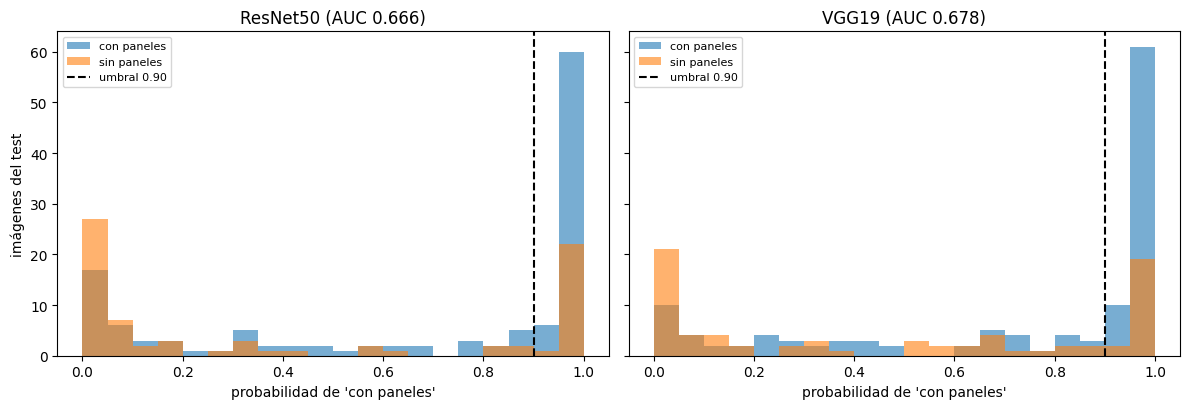

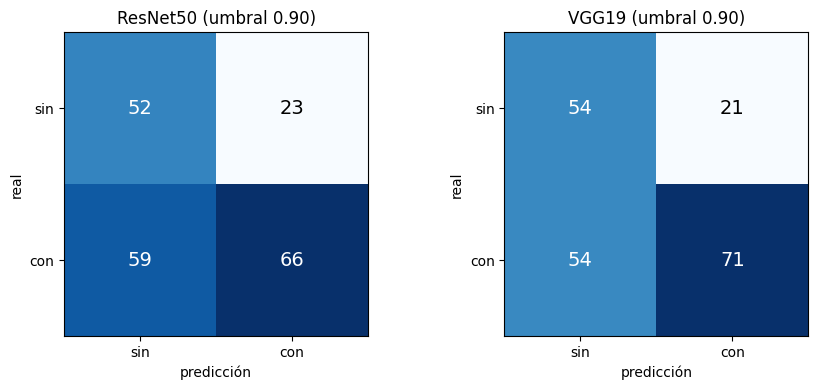

In [ ]:
fig, axes = plt.subplots(1, len(MODELOS), figsize=(6 * len(MODELOS), 4.2), squeeze=False, sharey=True)
for ax, (red, m) in zip(axes[0], MODELOS.items()):
    p = PROB_TEST[red]
    ax.hist(p[y_test == 1], bins=20, range=(0, 1), alpha=0.6, label="con paneles")
    ax.hist(p[y_test == 0], bins=20, range=(0, 1), alpha=0.6, label="sin paneles")
    ax.axvline(m["umbral"], color="k", linestyle="--", label=f"umbral {m['umbral']:.2f}")
    ax.set_title(f"{red} (AUC {roc_auc_score(y_test, p):.3f})")
    ax.set_xlabel("probabilidad de 'con paneles'")
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel("imágenes del test")
plt.tight_layout()
plt.show()

# Matrices de confusión con el umbral del cross validation
fig, axes = plt.subplots(1, len(MODELOS), figsize=(4.5 * len(MODELOS), 4), squeeze=False)
for ax, (red, m) in zip(axes[0], MODELOS.items()):
    cm = confusion_matrix(y_test, (PROB_TEST[red] >= m["umbral"]).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=14,
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["sin", "con"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["sin", "con"])
    ax.set_xlabel("predicción"); ax.set_ylabel("real")
    ax.set_title(f"{red} (umbral {m['umbral']:.2f})")
plt.tight_layout()
plt.show()

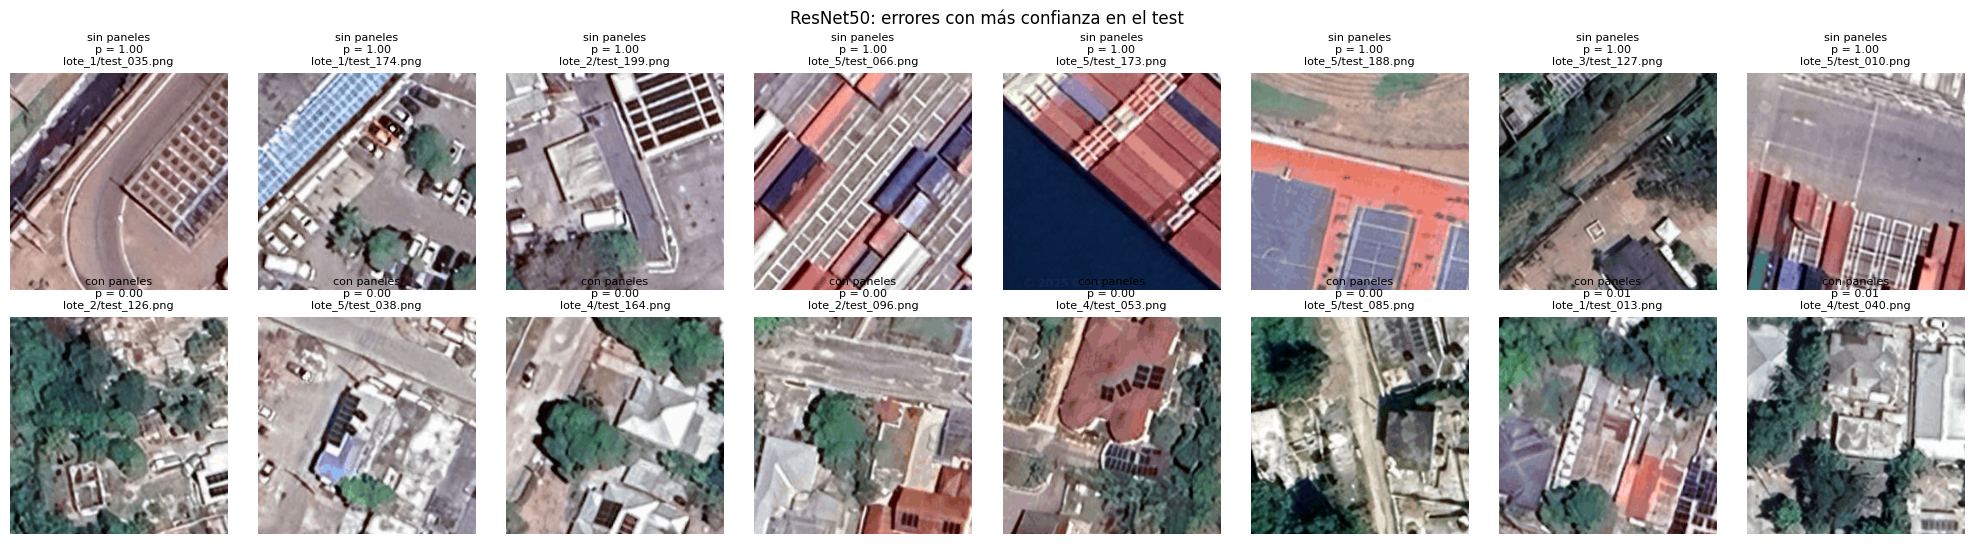

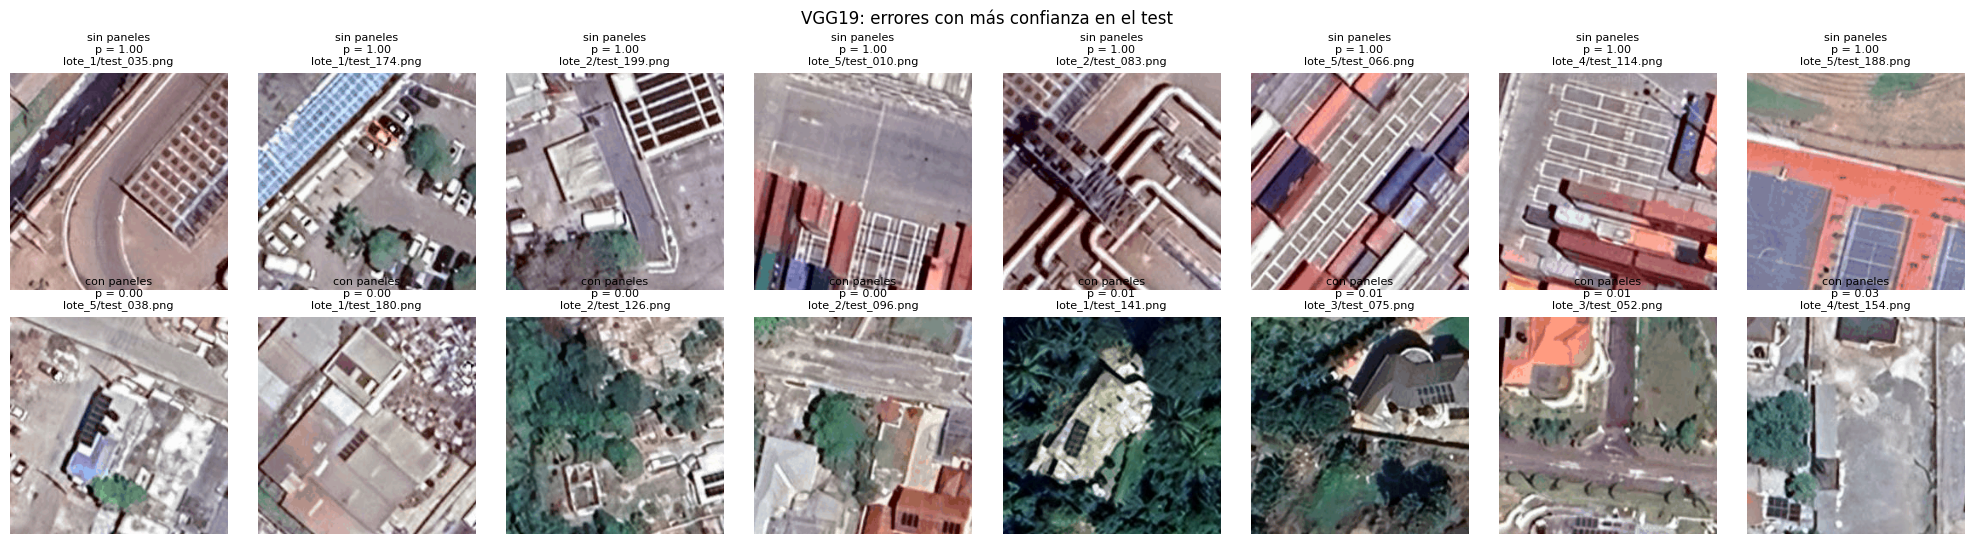

In [ ]:
# Errores con más confianza de cada red: negativas con probabilidad más alta y positivas con la más baja
for red in MODELOS:
    p = PROB_TEST[red]
    fp_conf = np.where(y_test == 0)[0][np.argsort(-p[y_test == 0])][:8]
    fn_conf = np.where(y_test == 1)[0][np.argsort(p[y_test == 1])][:8]
    fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
    for fila, (indices, titulo) in enumerate([(fp_conf, "sin paneles"), (fn_conf, "con paneles")]):
        for ax, k in zip(axes[fila], indices):
            ax.imshow(X_test[k])
            ax.set_title(f"{titulo}\np = {p[k]:.2f}\n{ETIQUETAS_TEST.archivo[k]}", fontsize=8)
            ax.axis("off")
    fig.suptitle(f"{red}: errores con más confianza en el test")
    plt.tight_layout()
    plt.show()